**Advanced Array Mathematics & Array Transformations**

In [1]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.4.6


1. Broadcasting in NumPy
1.1 Introduction to Broadcasting

In [2]:
measurements = np.array([10, 20, 30, 40])
correction = 5

print("Original:", measurements)
print("Correction:", correction)
print("After broadcasting:", measurements + correction)
print("Original remains:", measurements)

Original: [10 20 30 40]
Correction: 5
After broadcasting: [15 25 35 45]
Original remains: [10 20 30 40]


1.2 Broadcasting Rules

In [4]:
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", row_adjustment.shape)
print("Broadcast result shape:", (matrix + row_adjustment).shape)
print(matrix + row_adjustment)

# Contoh yang tidak kompatibel: (2, 3) dan (2,)
incompatible = np.array([1, 2])
try:
    print(matrix + incompatible)
except ValueError as error:
    print("Incompatible shapes:", error)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Broadcast result shape: (2, 3)
[[11 22 33]
 [41 52 63]]
Incompatible shapes: operands could not be broadcast together with shapes (2,3) (2,) 


1.3 Shape Compatibility

In [6]:
column_vector = np.array([[10],
                          [20],
                          [30]])
row_vector = np.array([[1, 2, 3, 4]])

combined = column_vector + row_vector

print("Column shape:", column_vector.shape)
print("Row shape:", row_vector.shape)
print("Compatible result shape:", np.broadcast_shapes(column_vector.shape, row_vector.shape))
print("Combined array:")
print(combined)

Column shape: (3, 1)
Row shape: (1, 4)
Compatible result shape: (3, 4)
Combined array:
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


1.4 Broadcasting Across Rows and Columns

In [8]:
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

column_bonus = np.array([2, 3, 5])
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)

print("Bonus per column (applies to each row):")
print(scores + column_bonus)
print("Bonus per row (applies to each column):")
print(scores + row_bonus)
print("Row bonus shape:", row_bonus.shape)

Bonus per column (applies to each row):
[[ 72  83  95]
 [ 77  88 100]
 [ 62  73  85]]
Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)


In [10]:
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("Column means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Means after centering:", np.mean(centered_scores, axis=0))

Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Means after centering: [4.73695157e-15 4.73695157e-15 4.73695157e-15]


2. Saving and Loading Arrays
2.1 Working with .npy Files

In [13]:
rainfall_data = np.array([[12.5, 8.0, 5.5],
                          [10.0, 15.5, 7.0],
                          [20.0, 11.0, 9.5]])

# Menyiapkan file untuk contoh loading pada subsection berikutnya
np.save("week11_rainfall.npy", rainfall_data)
print("Prepared file: week11_rainfall.npy")
print("Original shape:", rainfall_data.shape)
print("Original dtype:", rainfall_data.dtype)

Prepared file: week11_rainfall.npy
Original shape: (3, 3)
Original dtype: float64


2.2 Loading Arrays (np.load)

In [15]:
loaded_rainfall = np.load("week11_rainfall.npy", allow_pickle=False)

print("Loaded rainfall:")
print(loaded_rainfall)
print("Loaded shape:", loaded_rainfall.shape)

Loaded rainfall:
[[12.5  8.   5.5]
 [10.  15.5  7. ]
 [20.  11.   9.5]]
Loaded shape: (3, 3)


2.3 Saving Arrays (np.save)

In [17]:
exam_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

np.save("week11_exam_scores.npy", exam_scores)
print("Saved file: week11_exam_scores.npy")
print("Saved array:")
print(exam_scores)

Saved file: week11_exam_scores.npy
Saved array:
[[80 85 90]
 [70 75 80]
 [90 92 94]]


2.4 Inspecting Loaded Arrays

In [19]:
loaded_scores = np.load("week11_exam_scores.npy", allow_pickle=False)

print("Shape:", loaded_scores.shape)
print("Number of dimensions:", loaded_scores.ndim)
print("Data type:", loaded_scores.dtype)
print("First student's scores:", loaded_scores[0, :])
print("Same values and shape:", np.array_equal(exam_scores, loaded_scores))

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
First student's scores: [80 85 90]
Same values and shape: True


3. Image Arrays and Transformations
3.1 Understanding RGB and RGBA Arrays

In [21]:
# Gambar RGB sederhana: 3 baris x 3 kolom x 3 kanal warna
rgb_image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]]
], dtype=np.uint8)

alpha_channel = np.full((*rgb_image.shape[:2], 1), 255, dtype=np.uint8)
rgba_image = np.concatenate((rgb_image, alpha_channel), axis=2)

print("RGB shape:", rgb_image.shape)
print("RGBA shape:", rgba_image.shape)
print("Top-left RGB pixel:", rgb_image[0, 0])
print("Top-left RGBA pixel:", rgba_image[0, 0])

RGB shape: (3, 3, 3)
RGBA shape: (3, 3, 4)
Top-left RGB pixel: [255   0   0]
Top-left RGBA pixel: [255   0   0 255]


3.2 Selecting Image Color Channels¶

In [23]:
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print("Red shape:", red_channel.shape)
print("Red shape with 0:1:", rgb_image[:, :, 0:1].shape)

Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]
Red shape: (3, 3)
Red shape with 0:1: (3, 3, 1)


3.3 Manipulating Pixel Values

In [25]:
# Gunakan tipe lebih besar untuk menghindari overflow uint8
brightened_image = np.clip(rgb_image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

less_red_image = rgb_image.copy()
less_red_image[:, :, 0] = 0

print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Pixel without red [0, 0]:", less_red_image[0, 0])
print("Original image remains:", rgb_image[0, 0])

Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 40 255 255]
Original pixel [0, 0]: [255   0   0]
Pixel without red [0, 0]: [0 0 0]
Original image remains: [255   0   0]


3.4 Flipping Arrays (np.flip)

In [27]:
vertical_flip = np.flip(rgb_image, axis=0)
horizontal_flip = np.flip(rgb_image, axis=1)

print("Original red channel:")
print(rgb_image[:, :, 0])
print("Vertical flip (axis=0):")
print(vertical_flip[:, :, 0])
print("Horizontal flip (axis=1):")
print(horizontal_flip[:, :, 0])
print("Flipped shape:", horizontal_flip.shape)

Original red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Vertical flip (axis=0):
[[255 128   0]
 [255   0 255]
 [255   0   0]]
Horizontal flip (axis=1):
[[  0   0 255]
 [255   0 255]
 [  0 128 255]]
Flipped shape: (3, 3, 3)


In [29]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.11.0


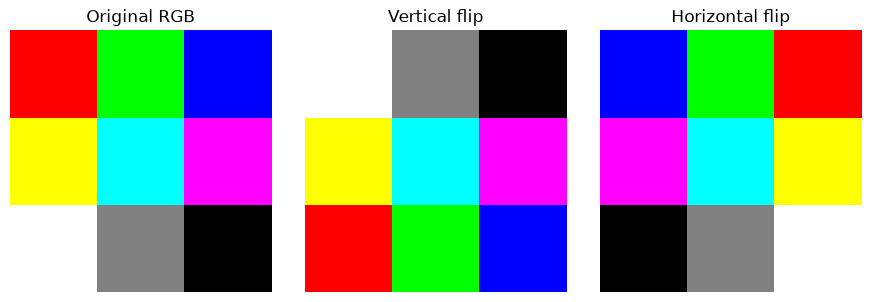

In [31]:
try:
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(9, 3))
    for axis, picture, label in zip(
        axes,
        [rgb_image, vertical_flip, horizontal_flip],
        ["Original RGB", "Vertical flip", "Horizontal flip"]
    ):
        axis.imshow(picture)
        axis.set_title(label)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib belum terpasang. instal matplotlib.")

4. Transposing Arrays
4.1 Array Transposition

In [33]:
data_matrix = np.array([[1, 2, 3],
                        [4, 5, 6]])

print("Original:")
print(data_matrix)
print("Shape:", data_matrix.shape)
print("Transposed:")
print(data_matrix.T)
print("Transposed shape:", np.transpose(data_matrix).shape)
print("1D transpose shape:", np.array([1, 2, 3]).T.shape)

Original:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Transposed:
[[1 4]
 [2 5]
 [3 6]]
Transposed shape: (3, 2)
1D transpose shape: (3,)


4.2 Transposing by Axis

In [35]:
data_3d = np.arange(24).reshape(2, 3, 4)
reordered = np.transpose(data_3d, axes=(1, 0, 2))

print("=== ORIGINAL ARRAY ===")
print("Shape:", data_3d.shape)
print(data_3d)

print("\nLayer 0:")
print(data_3d[0])

print("\nLayer 1:")
print(data_3d[1])

print("\n=== TRANSPOSED ARRAY ===")
print("Shape:", reordered.shape)
print(reordered)

print("\nLayer 0:")
print(reordered[0])

print("\nLayer 1:")
print(reordered[1])

print("\nLayer 2:")
print(reordered[2])

print("\n=== ELEMENT COMPARISON ===")
print("Original [1, 2, 3]:", data_3d[1, 2, 3])
print("Transposed [2, 1, 3]:", reordered[2, 1, 3])

print("\n=== SWAPAXES ===")
print(np.swapaxes(data_3d, 0, 1))

=== ORIGINAL ARRAY ===
Shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Layer 1:
[[12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

=== TRANSPOSED ARRAY ===
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [12 13 14 15]]

Layer 1:
[[ 4  5  6  7]
 [16 17 18 19]]

Layer 2:
[[ 8  9 10 11]
 [20 21 22 23]]

=== ELEMENT COMPARISON ===
Original [1, 2, 3]: 23
Transposed [2, 1, 3]: 23

=== SWAPAXES ===
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]


5. Stacking and Splitting Arrays
5.1 Splitting Arrays (np.split)

In [37]:
monthly_values = np.array([10, 12, 15, 18, 20, 22])
first_half, second_half = np.split(monthly_values, 2)

print("First half:", first_half)
print("Second half:", second_half)

measurement_table = np.arange(1, 13).reshape(3, 4)
left_part, right_part = np.split(measurement_table, 2, axis=1)

print("Original table:")
print(measurement_table)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print("Unequal split example:", [part.tolist() for part in np.array_split(np.arange(7), 3)])

First half: [10 12 15]
Second half: [18 20 22]
Original table:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]
Unequal split example: [[0, 1, 2], [3, 4], [5, 6]]


5.2 Stacking Arrays (np.stack)

In [39]:
day_one = np.array([12, 15, 18])
day_two = np.array([10, 17, 20])

stacked_rows = np.stack((day_one, day_two), axis=0)
stacked_columns = np.stack((day_one, day_two), axis=1)

print("Original vector shape:", day_one.shape)
print("Stacked by rows:")
print(stacked_rows)
print("Shape:", stacked_rows.shape)
print("Stacked by columns:")
print(stacked_columns)
print("Shape:", stacked_columns.shape)

Original vector shape: (3,)
Stacked by rows:
[[12 15 18]
 [10 17 20]]
Shape: (2, 3)
Stacked by columns:
[[12 10]
 [15 17]
 [18 20]]
Shape: (3, 2)


5.3 Reshaping Split Arrays

In [41]:
first_block, second_block = np.split(measurement_table, 2, axis=1)
first_vector = first_block.reshape(-1)
second_vector = second_block.reshape(-1)
reshaped_and_stacked = np.stack((first_vector, second_vector), axis=0)

print("Shape of each split block:", first_block.shape)
print("Shape after reshape:", first_vector.shape)
print("Reshaped and stacked:")
print(reshaped_and_stacked)
print("New shape:", reshaped_and_stacked.shape)

Shape of each split block: (3, 2)
Shape after reshape: (6,)
Reshaped and stacked:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
New shape: (2, 6)


6. Independent Student Exercises

Exercise 1 — Broadcasting in NumPy
Gunakan matriks berikut:

scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])
Tambahkan bonus [5, 3, 2] pada setiap kolom menggunakan broadcasting.
Tambahkan bonus [1, 4, 2] pada setiap baris dengan reshape(-1, 1).
Hitung rata-rata masing-masing kolom dengan keepdims=True, lalu kurangkan dari scores.
Tampilkan .shape untuk setiap array bonus dan hasil perhitungan.

In [43]:
#Jawaban :
# Data awal
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

# 1. Menambahkan bonus pada setiap kolom
column_bonus = np.array([5, 3, 2])
column_result = scores + column_bonus

print("Bonus per column (applies to each row):")
print(column_result)
print("Column bonus shape:", column_bonus.shape)
print("Column result shape:", column_result.shape)


# 2. Menambahkan bonus pada setiap baris
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)
row_result = scores + row_bonus

print("\nBonus per row (applies to each column):")
print(row_result)
print("Row bonus shape:", row_bonus.shape)
print("Row result shape:", row_result.shape)


# 3. Menghitung rata-rata setiap kolom
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("\nColumn means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Centered scores shape:", centered_scores.shape)

Bonus per column (applies to each row):
[[75 83 92]
 [80 88 97]
 [65 73 82]]
Column bonus shape: (3,)
Column result shape: (3, 3)

Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)
Row result shape: (3, 3)

Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Centered scores shape: (3, 3)


Exercise 2 — Saving and Loading Arrays¶
Gunakan temperatures = np.array([[29, 31, 30], [28, 32, 33], [27, 30, 31]]).

Simpan array ke file week11_temperatures.npy menggunakan np.save().
Buka kembali dengan np.load() dan simpan pada variabel baru.
Periksa .shape, .ndim, dan .dtype dari hasil pemuatan.
Gunakan np.array_equal() untuk memeriksa kesamaan array asli dan hasil pemuatan.

In [45]:
#Jawaban 
# Data awal
temperatures = np.array([[29, 31, 30],
                         [28, 32, 33],
                         [27, 30, 31]])

# 1. Menyimpan array ke file .npy
np.save("week11_temperatures.npy", temperatures)

print("Saved file: week11_temperatures.npy")
print("Saved array:")
print(temperatures)


# 2. Membuka kembali array yang telah disimpan
loaded_temperatures = np.load("week11_temperatures.npy", allow_pickle=False)

print("\nLoaded temperatures:")
print(loaded_temperatures)


# 3. Memeriksa struktur array
print("\nShape:", loaded_temperatures.shape)
print("Number of dimensions:", loaded_temperatures.ndim)
print("Data type:", loaded_temperatures.dtype)


# 4. Memeriksa kesamaan array
print("Same values and shape:", np.array_equal(temperatures, loaded_temperatures))

Saved file: week11_temperatures.npy
Saved array:
[[29 31 30]
 [28 32 33]
 [27 30 31]]

Loaded temperatures:
[[29 31 30]
 [28 32 33]
 [27 30 31]]

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
Same values and shape: True


Exercise 3 — Image Arrays and Transformations
Gunakan gambar RGB berikut:

image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)
Tampilkan bentuk gambar dan matriks kanal Red, Green, dan Blue.
Buat salinan gambar lalu ubah seluruh nilai kanal Blue menjadi 0.
Tambahkan kecerahan 30 pada semua kanal dengan astype(), np.clip(), dan astype(np.uint8).
Balik gambar secara horizontal serta vertikal menggunakan np.flip(), lalu periksa piksel pada posisi [0, 0] di setiap hasil.

In [46]:
# Data awal: Gambar RGB sederhana
image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)

# 1. Menampilkan bentuk gambar dan matriks setiap kanal warna
print("Image shape:", image.shape)

print("\nRed channel:")
print(image[:, :, 0])

print("\nGreen channel:")
print(image[:, :, 1])

print("\nBlue channel:")
print(image[:, :, 2])


# 2. Mengubah seluruh nilai kanal Blue menjadi 0
no_blue_image = image.copy()
no_blue_image[:, :, 2] = 0

print("\nImage without blue channel:")
print(no_blue_image)


# 3. Menambahkan kecerahan 30 pada semua kanal
brightened_image = np.clip(image.astype(np.int16) + 30, 0, 255).astype(np.uint8)

print("\nBrightened image:")
print(brightened_image)


# 4. Membalik gambar secara horizontal dan vertikal
horizontal_flip = np.flip(image, axis=1)
vertical_flip = np.flip(image, axis=0)

print("\nHorizontal flip:")
print(horizontal_flip)

print("\nVertical flip:")
print(vertical_flip)

print("\nOriginal pixel [0, 0]:", image[0, 0])
print("Horizontal flip pixel [0, 0]:", horizontal_flip[0, 0])
print("Vertical flip pixel [0, 0]:", vertical_flip[0, 0])

Image shape: (2, 2, 3)

Red channel:
[[255   0]
 [  0 255]]

Green channel:
[[  0 255]
 [  0 255]]

Blue channel:
[[  0   0]
 [255 255]]

Image without blue channel:
[[[255   0   0]
  [  0 255   0]]

 [[  0   0   0]
  [255 255   0]]]

Brightened image:
[[[255  30  30]
  [ 30 255  30]]

 [[ 30  30 255]
  [255 255 255]]]

Horizontal flip:
[[[  0 255   0]
  [255   0   0]]

 [[255 255 255]
  [  0   0 255]]]

Vertical flip:
[[[  0   0 255]
  [255 255 255]]

 [[255   0   0]
  [  0 255   0]]]

Original pixel [0, 0]: [255   0   0]
Horizontal flip pixel [0, 0]: [  0 255   0]
Vertical flip pixel [0, 0]: [  0   0 255]


Exercise 4 — Transposing Arrays
Gunakan arr = np.arange(24).reshape(2, 3, 4).

Periksa .shape array awal.
Gunakan np.transpose() untuk mengubah urutan sumbu menjadi (1, 0, 2).
Gunakan np.swapaxes() untuk menghasilkan bentuk array yang sama.
Buat gambar image = np.zeros((4, 5, 3)), ubah dari HWC menjadi CHW, lalu kembalikan ke HWC.

In [48]:
# Data awal
arr = np.arange(24).reshape(2, 3, 4)

# 1. Memeriksa bentuk array awal
print("Original array:")
print(arr)
print("Original shape:", arr.shape)


# 2. Mengubah urutan sumbu menggunakan np.transpose()
transposed = np.transpose(arr, axes=(1, 0, 2))

print("\nTransposed array:")
print(transposed)
print("Transposed shape:", transposed.shape)


# 3. Mengubah sumbu menggunakan np.swapaxes()
swapped = np.swapaxes(arr, 0, 1)

print("\nSwapped array:")
print(swapped)
print("Swapped shape:", swapped.shape)

print("Same result:", np.array_equal(transposed, swapped))


# 4. Mengubah gambar dari HWC menjadi CHW
image = np.zeros((4, 5, 3))

print("\nOriginal image shape (HWC):", image.shape)

image_chw = np.transpose(image, axes=(2, 0, 1))

print("CHW image shape:", image_chw.shape)

# Mengembalikan gambar dari CHW menjadi HWC
image_hwc = np.transpose(image_chw, axes=(1, 2, 0))

print("Restored image shape (HWC):", image_hwc.shape)

Original array:
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]
Original shape: (2, 3, 4)

Transposed array:
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]
Transposed shape: (3, 2, 4)

Swapped array:
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]
Swapped shape: (3, 2, 4)
Same result: True

Original image shape (HWC): (4, 5, 3)
CHW image shape: (3, 4, 5)
Restored image shape (HWC): (4, 5, 3)


Exercise 5 — Stacking and Splitting Arrays
Gunakan data = np.arange(1, 13).reshape(3, 4).

Bagi data menjadi dua bagian menurut kolom menggunakan np.split().
Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan reshape(-1).
Gabungkan kedua vektor memakai np.stack(axis=0) dan periksa bentuknya.
Gunakan np.array_split() untuk membagi np.arange(10) menjadi tiga bagian; bandingkan ukuran setiap bagian.